# Unsupervised Tasks: Bike Trip and Stations Profiles
## 1. Data Exploration and Preprocessing Task
Préparation du code avec import des librairies et des fichiers csv

In [2]:
# Import des librairies
import matplotlib.pyplot as plt
import sklearn as sk
import seaborn as sns
import pandas as pd

In [3]:
# Read CSV files
bike_types_df = pd.read_csv("../csv/bike_types.csv", sep = ",")
bikes_df = pd.read_csv("../csv/bikes.csv", sep = ",")
cities_df = pd.read_csv('../csv/cities.csv', sep = ",")
stations_status_df = pd.read_csv("../csv/stations_status.csv", sep = ",")
stations_df = pd.read_csv("../csv/stations.csv", sep = ",")
trips_small_df = pd.read_csv("../csv/trips_small.csv", sep = ",")

### 1.1 Représentation graphique des données
#### Pour le fichier `bike_types.csv`

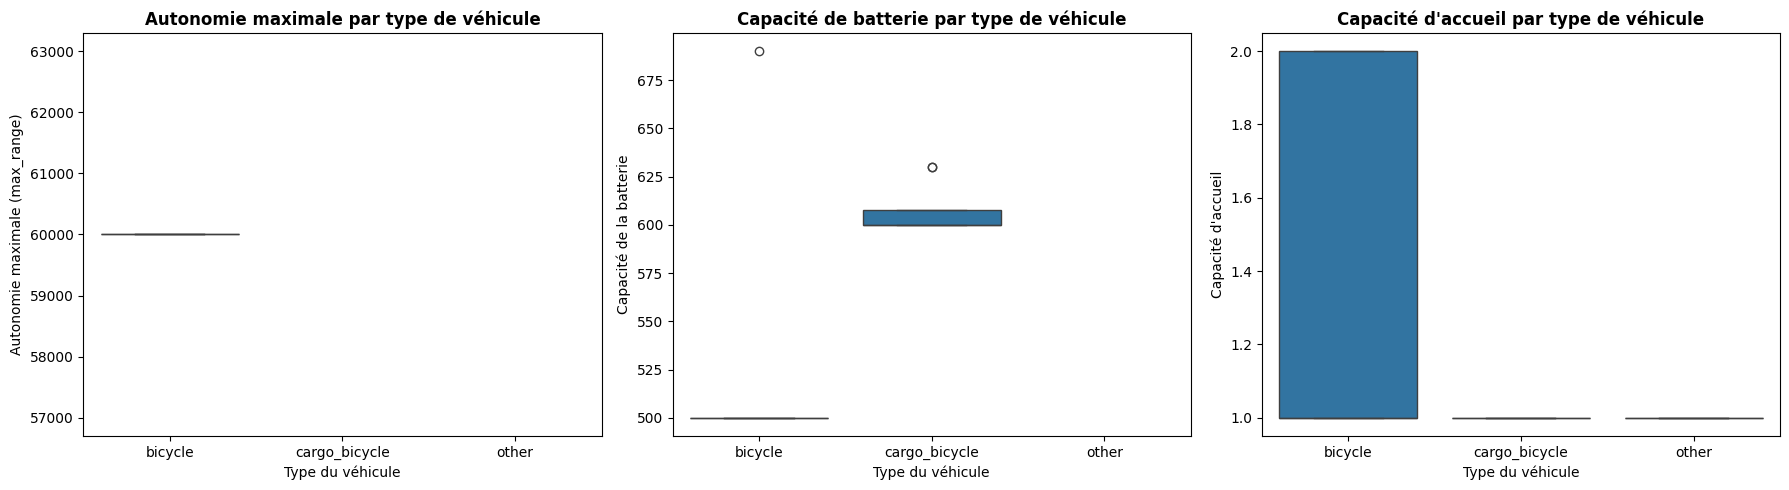

In [4]:
# Par form_factor
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Max_Range
sns.boxplot(data=bike_types_df, x='form_factor', y='max_range', ax=axes[0])
axes[0].set_title("Autonomie maximale par type de véhicule", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Type du véhicule", fontsize=10)
axes[0].set_ylabel("Autonomie maximale (max_range)", fontsize=10)

# Battery_Capacity
sns.boxplot(data=bike_types_df, x='form_factor', y='battery_capacity', ax=axes[1])
axes[1].set_title("Capacité de batterie par type de véhicule", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Type du véhicule", fontsize=10)
axes[1].set_ylabel("Capacité de la batterie", fontsize=10)

# Rider_Capacity
sns.boxplot(data=bike_types_df, x='form_factor', y='rider_capacity', ax=axes[2])
axes[2].set_title("Capacité d'accueil par type de véhicule", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Type du véhicule", fontsize=10)
axes[2].set_ylabel("Capacité d'accueil", fontsize=10)

plt.tight_layout()
plt.show()

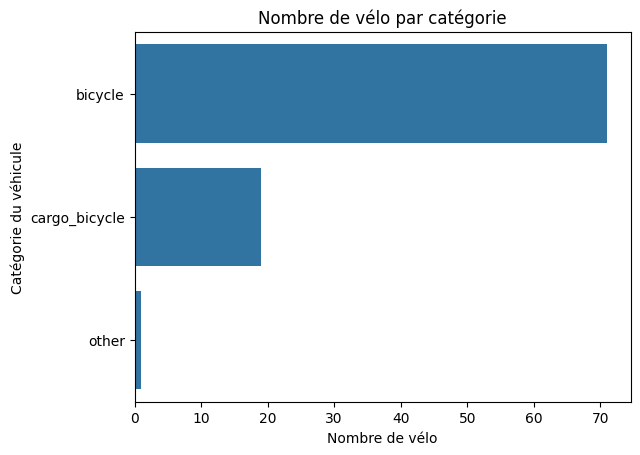

In [5]:
grouped_form = bike_types_df.groupby("form_factor").size().reset_index(name = "count")
grouped_form = grouped_form.sort_values(["count"], ascending=False)

plt.figure()
sns_barplot = sns.barplot(grouped_form, x="count", y="form_factor")
sns_barplot.set(
    title = "Nombre de vélo par catégorie",
    xlabel = "Nombre de vélo",
    ylabel = "Catégorie du véhicule"
)
plt.show()

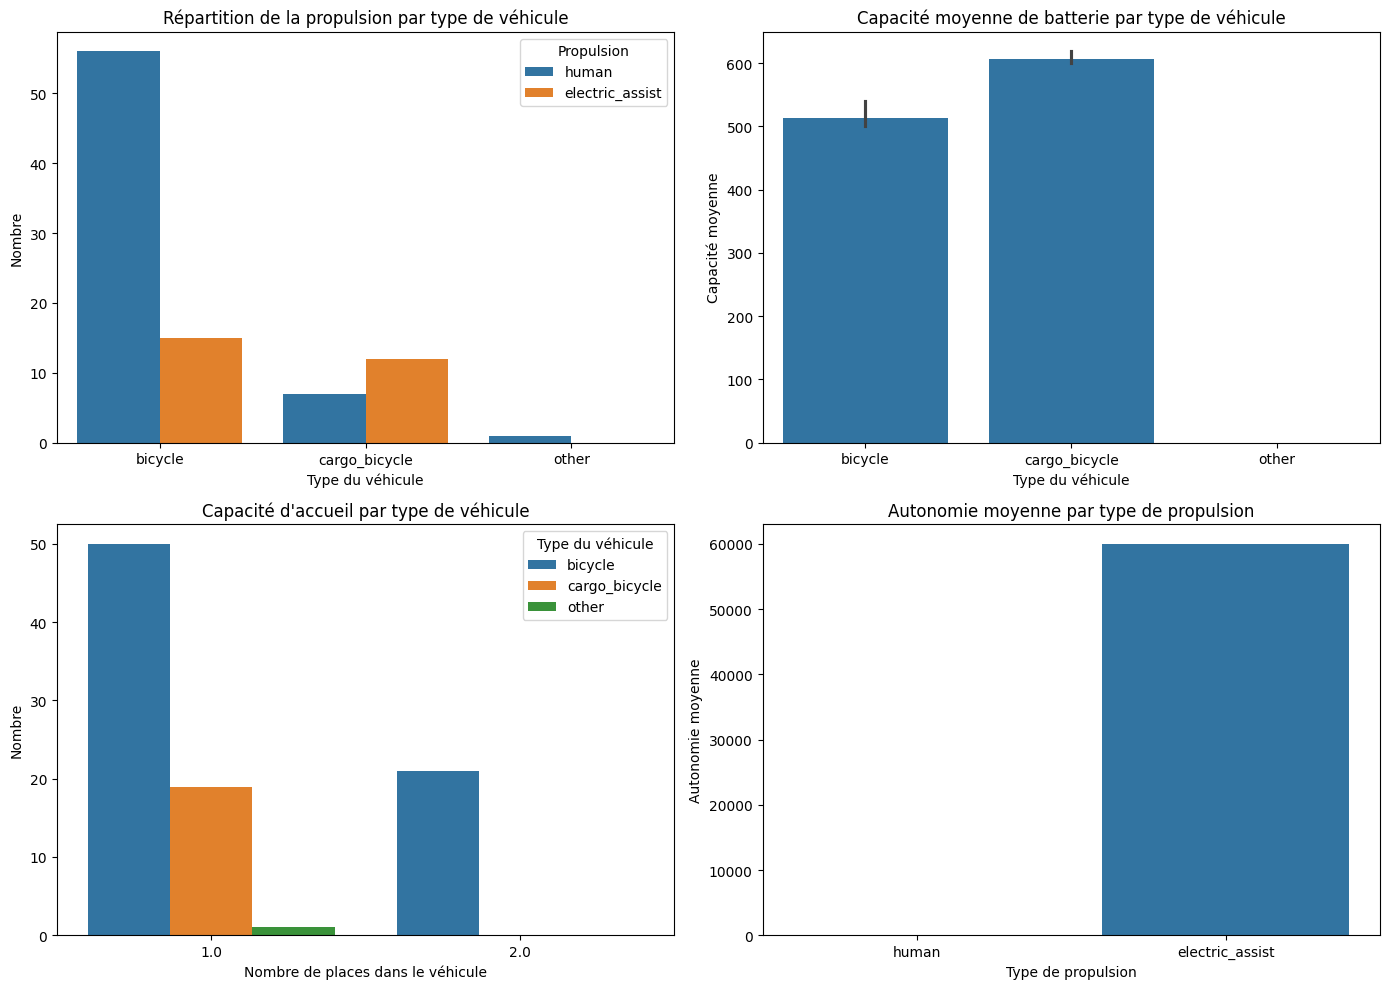

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=bike_types_df, x='form_factor', hue='propulsion_type', ax=axes[0, 0])
axes[0, 0].set_title("Répartition de la propulsion par type de véhicule")
axes[0, 0].set_xlabel("Type du véhicule")
axes[0, 0].set_ylabel("Nombre")
axes[0, 0].legend(title="Propulsion")

sns.barplot(data=bike_types_df, x='form_factor', y='battery_capacity', estimator='mean', ax=axes[0, 1])
axes[0, 1].set_title("Capacité moyenne de batterie par type de véhicule")
axes[0, 1].set_xlabel("Type du véhicule")
axes[0, 1].set_ylabel("Capacité moyenne")

sns.countplot(data=bike_types_df, x='rider_capacity', hue='form_factor', ax=axes[1, 0])
axes[1, 0].set_title("Capacité d'accueil par type de véhicule")
axes[1, 0].set_xlabel("Nombre de places dans le véhicule")
axes[1, 0].set_ylabel("Nombre")
axes[1, 0].legend(title="Type du véhicule")

sns.barplot(data=bike_types_df, x='propulsion_type', y='max_range', estimator='mean', ax=axes[1, 1])
axes[1, 1].set_title("Autonomie moyenne par type de propulsion")
axes[1, 1].set_xlabel("Type de propulsion")
axes[1, 1].set_ylabel("Autonomie moyenne")

plt.tight_layout()
plt.show()

### 1.2 Analyse de la forme des données
#### Pour le fichier `bike_types.csv`

In [8]:
bike_types_df.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
bike_types_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     str    
 2   name              91 non-null     str    
 3   description       51 non-null     str    
 4   form_factor       91 non-null     str    
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     str    
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 8.6 KB


In [21]:
bike_types_df.describe()

,id,rider_capacity,max_range,battery_capacity
count,121.000000,91.000000,15.0,22.000000
mean,134.454545,1.230769,60000.0,547.727273
std,77.738450,0.423659,0.0,61.638873
min,0.000000,1.000000,60000.0,500.000000
25%,72.000000,1.000000,60000.0,500.000000
50%,149.000000,1.000000,60000.0,500.000000
75%,201.000000,1.000000,60000.0,600.000000
max,254.000000,2.000000,60000.0,690.000000


In [9]:
# Description du dataframe (dimensions, type, doublons, valeurs manquantes, ...)
print("Dimensions du dataframe : ", bike_types_df.shape)
print("Nombre de doublons : ", bike_types_df.duplicated().sum(), "\n")
print("Types de données :\n", bike_types_df.dtypes, "\n")
print("Nombre de NaN par colonne :\n", bike_types_df.isna().sum())

Dimensions du dataframe :  (121, 9)
Nombre de doublons :  0 

Types de données :
 id                    int64
vehicle_image           str
name                    str
description             str
form_factor             str
rider_capacity      float64
propulsion_type         str
max_range           float64
battery_capacity    float64
dtype: object 

Nombre de NaN par colonne :
 id                    0
vehicle_image        30
name                 30
description          70
form_factor          30
rider_capacity       30
propulsion_type      30
max_range           106
battery_capacity     99
dtype: int64


In [10]:
print(bike_types_df["form_factor"].unique(), "\n")
print(bike_types_df["propulsion_type"].unique())

<StringArray>
[nan, 'bicycle', 'cargo_bicycle', 'other']
Length: 4, dtype: str 

<StringArray>
[nan, 'human', 'electric_assist']
Length: 3, dtype: str


In [11]:
print(bike_types_df["name"].unique())

<StringArray>
[                              nan,                         'Comfort',
   'Rower z fotelikiem dziecięcym',                          'Tandem',
                 'Elektricno kolo',                     'e-CARGObike',
            'Rowerek dziecięcy 6+',     '3-rychlostní SMARTbike 2.0.',
       'e-SMARTbike 2.0 with RFID',         '28 Zoll - Tourenfahrrad',
                'e-SMARTbike 2.0.',          'Smartbike 2.0 (B) 2019',
                 'e-SMARTbike 1.0',                       'UsedomRad',
               'UsedomRad Classic',         '20 Zoll - Kinderfahrrad',
         '24 Zoll - Kinderfahrrad',                 'Z wałem kardana',
          '7-rychlostní SMARTbike',                 'e-Bike "LaBigi"',
                          'E-Bike',     '7-rychlostní SMARTbike 2.0.',
                     'e-Cargobike',                       'CARGObike',
     '8-rychlostní SMARTbike 2.0.',                  'with Framelock',
          '8-rychlostní SMARTbike',            'CARGObike (3 wh

*NB*: Est-ce que c'est intéressant de nettoyer le nom des véhicules ?

### 1.3 Modification des dataframes

In [12]:
# Cellule pour nettoyer les noms

In [13]:
# Pour les lignes NaN, voir comment elles sont utilisées dans les autres dataset :
# On regarde la dépendance avec le dataframe bikes
# Prend un id de bike_type où la ligne est NaN dans le dataframe pour voir à quoi ça ressembe
bikes_df[bikes_df['bike_type_id'] == 152]

,id,bike_type_id,computer_id
506,68228,152,0
507,67230,152,0
508,67297,152,0
696,68408,152,0
764,66018,152,0
...,...,...,...
28182,68470,152,0
28183,68905,152,0
28184,67330,152,0
28677,68095,152,0


In [14]:
# Les éléments de bikes qui ont un bike_type où la ligne est NaN dans bike_types n'apportent pas beaucoup d'info
# On regarde le dataframe trips_small pour voir comment ils sont utilisés
trips_small_df[trips_small_df["bike_id"] == 67257]

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
400108,67257,620,1.666766e+09,16.882574,52.343290,16.902992,52.372152,14043132.0,373709.0,NaN,NaN,1080.0,3496.042754
400109,67257,394,1.666974e+09,16.886571,52.353718,16.902992,52.372152,4328771.0,373709.0,NaN,NaN,840.0,2333.415628


### 1.4 Création et analyse de la dataframe principale

In [15]:
# On rassemble les trois dataframe (bike_types, bikes, et trips_small) car tous reliés entre eux
bike_sub = bikes_df[['id', 'bike_type_id']]
bike_type_sub = bike_types_df[['id', 'name', 'form_factor', 'propulsion_type', 'max_range', "battery_capacity"]]

trips_with_bikes = pd.merge(trips_small_df, bike_sub, left_on='bike_id', right_on='id', how='left')
complete_df = pd.merge(trips_with_bikes, bike_type_sub, left_on="bike_type_id", right_on="id", how="left")
complete_df = complete_df.drop(columns=['id_x', 'id_y'])

complete_df

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,bike_type_id,name,form_factor,propulsion_type,max_range,battery_capacity
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806,15,with Fork lock,bicycle,human,NaN,NaN
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764,15,with Fork lock,bicycle,human,NaN,NaN
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620,15,with Fork lock,bicycle,human,NaN,NaN
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250,15,with Fork lock,bicycle,human,NaN,NaN
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993,15,with Fork lock,bicycle,human,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0


#### Représentation graphique pour mieux visualiser les données et en extraire des informations

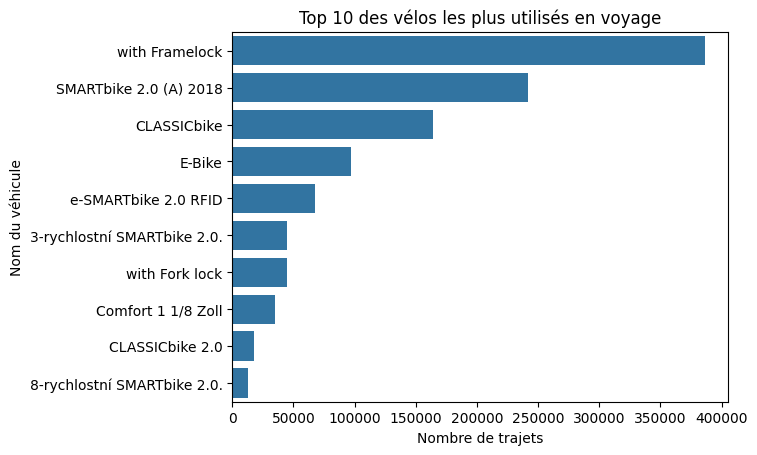

In [16]:
top_bikes = complete_df['name'].value_counts().head(10).reset_index()
top_bikes.columns = ['name', 'count']

plt.figure()
top_bikes_barplot = sns.barplot(data=top_bikes, x='count', y='name')
top_bikes_barplot.set_title("Top 10 des vélos les plus utilisés en voyage")
top_bikes_barplot.set_xlabel("Nombre de trajets")
top_bikes_barplot.set_ylabel("Nom du véhicule")
plt.show()

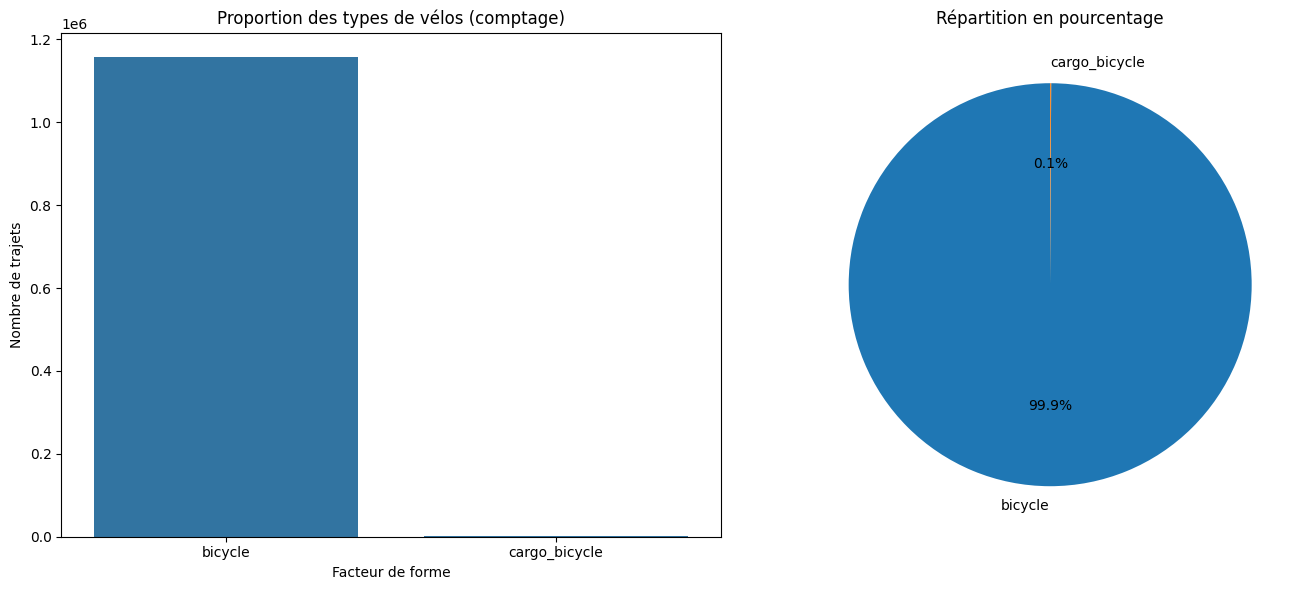

In [17]:

form_counts = complete_df['form_factor'].value_counts().reset_index()
form_counts.columns = ['form_factor', 'count']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=form_counts, x='form_factor', y='count', ax=axes[0])
axes[0].set_title("Proportion des types de vélos (comptage)")
axes[0].set_xlabel("Facteur de forme")
axes[0].set_ylabel("Nombre de trajets")

complete_df['form_factor'].value_counts().plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=90, 
    ax=axes[1]
)
axes[1].set_title("Répartition en pourcentage")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()